In [7]:
import pandas as pd

delays = pd.read_csv("../data/raw/Delays/Transparency 25-26 P04.csv", low_memory=False)

print(delays.shape)
print(list(delays.columns))
delays.head(3)

(465703, 40)
['FINANCIAL_YEAR_PERIOD', 'ORIGIN_DEPARTURE_DATE', 'TRUST_TRAIN_ID', 'PLANNED_ORIGIN_LOCATION_CODE', 'PLANNED_ORIGIN_WTT_DATETIME', 'PLANNED_ORIGIN_GBTT_DATETIME', 'PLANNED_DEST_LOCATION_CODE', 'PLANNED_DEST_WTT_DATETIME', 'PLANNED_DEST_GBTT_DATETIME', 'TRAIN_SERVICE_CODE', 'SERVICE_GROUP_CODE', 'TOC_CODE', 'ENGLISH_DAY_TYPE', 'APPLICABLE_TIMETABLE_FLAG', 'TRAIN_SCHEDULE_TYPE', 'TRACTION_TYPE', 'TRAILING_LOAD', 'TIMING_LOAD', 'UNIT_CLASS', 'INCIDENT_NUMBER', 'INCIDENT_CREATE_DATE', 'INCIDENT_START_DATETIME', 'INCIDENT_END_DATETIME', 'SECTION_CODE', 'NR_LOCATION_MANAGER', 'RESPONSIBLE_MANAGER', 'INCIDENT_REASON', 'ATTRIBUTION_STATUS', 'INCIDENT_EQUIPMENT', 'INCIDENT_DESCRIPTION', 'REACT_REASON', 'INCIDENT_RESP_TRAIN', 'RESP_TRAIN', 'REACT_TRAIN', 'EVENT_TYPE', 'START_STANOX', 'END_STANOX', 'EVENT_DATETIME', 'PFPI_MINUTES', 'NON_PFPI_MINUTES']


,FINANCIAL_YEAR_PERIOD,ORIGIN_DEPARTURE_DATE,TRUST_TRAIN_ID,PLANNED_ORIGIN_LOCATION_CODE,PLANNED_ORIGIN_WTT_DATETIME,PLANNED_ORIGIN_GBTT_DATETIME,PLANNED_DEST_LOCATION_CODE,PLANNED_DEST_WTT_DATETIME,PLANNED_DEST_GBTT_DATETIME,TRAIN_SERVICE_CODE,SERVICE_GROUP_CODE,TOC_CODE,ENGLISH_DAY_TYPE,APPLICABLE_TIMETABLE_FLAG,TRAIN_SCHEDULE_TYPE,TRACTION_TYPE,TRAILING_LOAD,TIMING_LOAD,UNIT_CLASS,INCIDENT_NUMBER,INCIDENT_CREATE_DATE,INCIDENT_START_DATETIME,INCIDENT_END_DATETIME,SECTION_CODE,NR_LOCATION_MANAGER,RESPONSIBLE_MANAGER,INCIDENT_REASON,ATTRIBUTION_STATUS,INCIDENT_EQUIPMENT,INCIDENT_DESCRIPTION,REACT_REASON,INCIDENT_RESP_TRAIN,RESP_TRAIN,REACT_TRAIN,EVENT_TYPE,START_STANOX,END_STANOX,EVENT_DATETIME,PFPI_MINUTES,NON_PFPI_MINUTES
0,2025/26_P04,22-JUN-25,009I17MD22,850,22-JUN-2025 08:52,22-JUN-2025 08:52,63631,22-JUN-2025 09:57,22-JUN-2025 09:57,81010001,GA01,GA,SU,Y,(V)STP Overlay,EMU,NaN,NaN,NaN,556218,21-JUN-2025 00:00,22-JUN-2025 00:01,22-JUN-2025 04:52,00750,OQQA,TGAZ,TN,Attribution Agreed,NaN,EUROSTAR INWARD PBN 22 06,NaN,NaN,NaN,NaN,M,850,850,22-JUN-2025 09:02,10.0,0.0
1,2025/26_P04,22-JUN-25,009I25MD22,950,22-JUN-2025 08:40,22-JUN-2025 08:40,63631,22-JUN-2025 11:57,22-JUN-2025 11:57,81010001,GA01,GA,SU,Y,(V)STP Overlay,EMU,NaN,NaN,NaN,556218,21-JUN-2025 00:00,22-JUN-2025 00:01,22-JUN-2025 04:52,00750,OQQA,TGAZ,TN,Attribution Agreed,NaN,EUROSTAR INWARD PBN 22 06,NaN,NaN,NaN,NaN,M,950,950,22-JUN-2025 08:44,4.0,0.0
2,2025/26_P04,22-JUN-25,009I35ML22,850,22-JUN-2025 12:56,22-JUN-2025 12:56,63631,22-JUN-2025 13:57,22-JUN-2025 13:57,81010001,GA01,GA,SU,Y,(V)STP Overlay,EMU,NaN,NaN,NaN,556218,21-JUN-2025 00:00,22-JUN-2025 00:01,22-JUN-2025 04:52,00750,OQQA,TGAZ,TN,Attribution Agreed,NaN,EUROSTAR INWARD PBN 22 06,NaN,NaN,NaN,NaN,M,850,850,22-JUN-2025 14:05,69.0,0.0


In [10]:
pd.set_option("display.max_columns", None)
print(delays.columns.tolist())

# Look for the columns that describe the cause of each incident
reason_cols = [c for c in delays.columns if "REASON" in c or "DESCRIPTION" in c]
for c in reason_cols:
    print("\n", c)
    print(delays[c].value_counts())

['FINANCIAL_YEAR_PERIOD', 'ORIGIN_DEPARTURE_DATE', 'TRUST_TRAIN_ID', 'PLANNED_ORIGIN_LOCATION_CODE', 'PLANNED_ORIGIN_WTT_DATETIME', 'PLANNED_ORIGIN_GBTT_DATETIME', 'PLANNED_DEST_LOCATION_CODE', 'PLANNED_DEST_WTT_DATETIME', 'PLANNED_DEST_GBTT_DATETIME', 'TRAIN_SERVICE_CODE', 'SERVICE_GROUP_CODE', 'TOC_CODE', 'ENGLISH_DAY_TYPE', 'APPLICABLE_TIMETABLE_FLAG', 'TRAIN_SCHEDULE_TYPE', 'TRACTION_TYPE', 'TRAILING_LOAD', 'TIMING_LOAD', 'UNIT_CLASS', 'INCIDENT_NUMBER', 'INCIDENT_CREATE_DATE', 'INCIDENT_START_DATETIME', 'INCIDENT_END_DATETIME', 'SECTION_CODE', 'NR_LOCATION_MANAGER', 'RESPONSIBLE_MANAGER', 'INCIDENT_REASON', 'ATTRIBUTION_STATUS', 'INCIDENT_EQUIPMENT', 'INCIDENT_DESCRIPTION', 'REACT_REASON', 'INCIDENT_RESP_TRAIN', 'RESP_TRAIN', 'REACT_TRAIN', 'EVENT_TYPE', 'START_STANOX', 'END_STANOX', 'EVENT_DATETIME', 'PFPI_MINUTES', 'NON_PFPI_MINUTES']

 INCIDENT_REASON
INCIDENT_REASON
OU    42228
TG    23880
IS    22774
XA    21242
ZS    16653
      ...  
OF        1
RW        1
TF        1
QP  

In [11]:
WEATHER_CODES = {
    "X1","X2","X4","X9","XJ","XT","XW",     # severe weather (external)
    "QH","QI","QJ",                          # leaf fall / adhesion
    "IW","IP","JT","JH","JK","J6","OG",      # weather affecting assets
}

delays["is_weather"] = delays["INCIDENT_REASON"].isin(WEATHER_CODES)

# Which weather codes appear, and how many delay minutes each caused
(delays[delays["is_weather"]]
   .groupby("INCIDENT_REASON")["PFPI_MINUTES"]
   .agg(rows="count", minutes="sum")
   .sort_values("minutes", ascending=False))

,rows,minutes
INCIDENT_REASON,,
JH,5810,19340.5
X4,2071,11255.0
JK,857,7111.0
XJ,387,4348.5
J6,340,1871.0
XW,68,460.0
IW,3,45.0
X2,8,45.0
QI,5,11.0


<Axes: title={'center': 'Weather-attributed delay minutes per day'}, xlabel='date'>

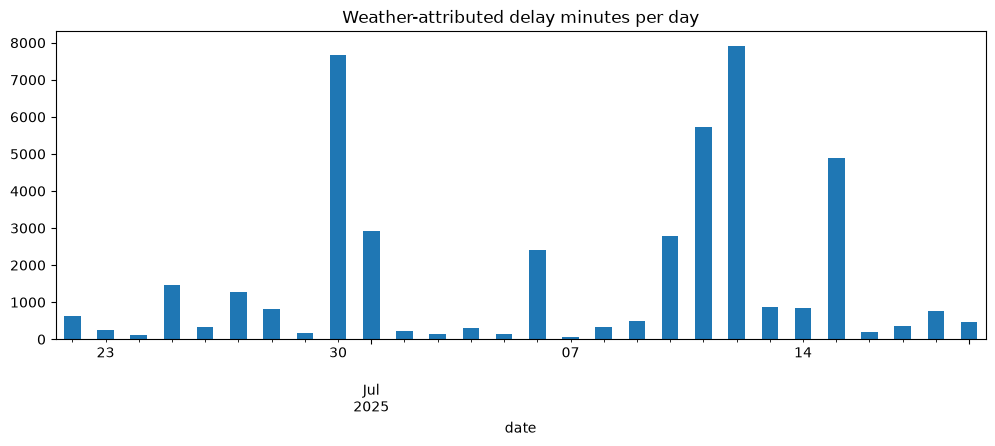

In [12]:
delays["date"] = pd.to_datetime(delays["ORIGIN_DEPARTURE_DATE"], format="%d-%b-%y")
daily = (delays[delays["is_weather"]]
           .groupby("date")["PFPI_MINUTES"].sum())
daily.plot(kind="bar", figsize=(12, 4), title="Weather-attributed delay minutes per day")

In [13]:
weather = pd.read_csv("../data/raw/weather_daily.csv", parse_dates=["time"])
temps = weather.pivot(index="time", columns="city", values="temperature_2m_max")

check = pd.DataFrame({"weather_delay_min": daily}).join(temps)
check.round(1)

,weather_delay_min,Birmingham,Bristol,Edinburgh,Glasgow,Leeds,London,Manchester,York
date,,,,,,,,,
2025-06-22,639.0,21.6,20.4,18.1,16.0,21.1,26.6,20.6,21.9
2025-06-23,247.0,18.5,17.7,16.5,15.0,16.9,22.7,17.2,18.0
2025-06-24,120.0,24.8,20.6,17.0,16.1,20.3,24.4,20.0,21.2
2025-06-25,1457.5,25.2,23.4,19.0,17.5,21.6,27.4,22.1,22.8
2025-06-26,319.0,21.5,18.5,17.7,16.4,21.1,24.1,19.7,22.7
2025-06-27,1278.0,25.0,25.1,20.9,19.2,24.0,27.0,23.7,25.9
2025-06-28,821.0,28.3,23.8,20.5,18.4,24.5,30.2,24.2,26.1
2025-06-29,165.0,25.6,23.8,22.9,19.9,23.1,29.8,22.9,25.5
2025-06-30,7657.5,30.3,29.7,23.5,21.2,28.8,31.9,28.7,29.4


In [14]:
rain = weather.pivot(index="time", columns="city", values="precipitation_sum")
rain.loc[["2025-07-06", "2025-07-15"]].round(1)

city,Birmingham,Bristol,Edinburgh,Glasgow,Leeds,London,Manchester,York
time,,,,,,,,
2025-07-06,5.7,1.4,4.2,5.4,10.9,3.8,6.1,5.4
2025-07-15,6.3,8.4,8.5,13.4,5.4,0.7,19.3,10.5
